In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [3]:
df = pd.read_csv("traffic.csv")

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [4]:
df.head()

,DateTime,Junction,Vehicles,ID
0,2015-11-01 00:00:00,1,15,20151101001
1,2015-11-01 01:00:00,1,13,20151101011
2,2015-11-01 02:00:00,1,10,20151101021
3,2015-11-01 03:00:00,1,7,20151101031
4,2015-11-01 04:00:00,1,9,20151101041


In [5]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Rows: 48120
Columns: 4


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48120 entries, 0 to 48119
Data columns (total 4 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   DateTime  48120 non-null  object
 1   Junction  48120 non-null  int64 
 2   Vehicles  48120 non-null  int64 
 3   ID        48120 non-null  int64 
dtypes: int64(3), object(1)
memory usage: 1.5+ MB


In [7]:
df.isnull().sum()

DateTime    0
Junction    0
Vehicles    0
ID          0
dtype: int64

In [8]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [9]:
df.describe()

,Junction,Vehicles,ID
count,48120.000000,48120.000000,4.812000e+04
mean,2.180549,22.791334,2.016330e+10
std,0.966955,20.750063,5.944854e+06
min,1.000000,1.000000,2.015110e+10
25%,1.000000,9.000000,2.016042e+10
50%,2.000000,15.000000,2.016093e+10
75%,3.000000,29.000000,2.017023e+10
max,4.000000,180.000000,2.017063e+10


In [10]:
df['DateTime'] = pd.to_datetime(df['DateTime'])

print(df['DateTime'].dtype)

datetime64[ns]


In [11]:
df['Hour'] = df['DateTime'].dt.hour
df['Day'] = df['DateTime'].dt.day
df['Month'] = df['DateTime'].dt.month
df['DayOfWeek'] = df['DateTime'].dt.dayofweek

df.head()

,DateTime,Junction,Vehicles,ID,Hour,Day,Month,DayOfWeek
0,2015-11-01 00:00:00,1,15,20151101001,0,1,11,6
1,2015-11-01 01:00:00,1,13,20151101011,1,1,11,6
2,2015-11-01 02:00:00,1,10,20151101021,2,1,11,6
3,2015-11-01 03:00:00,1,7,20151101031,3,1,11,6
4,2015-11-01 04:00:00,1,9,20151101041,4,1,11,6


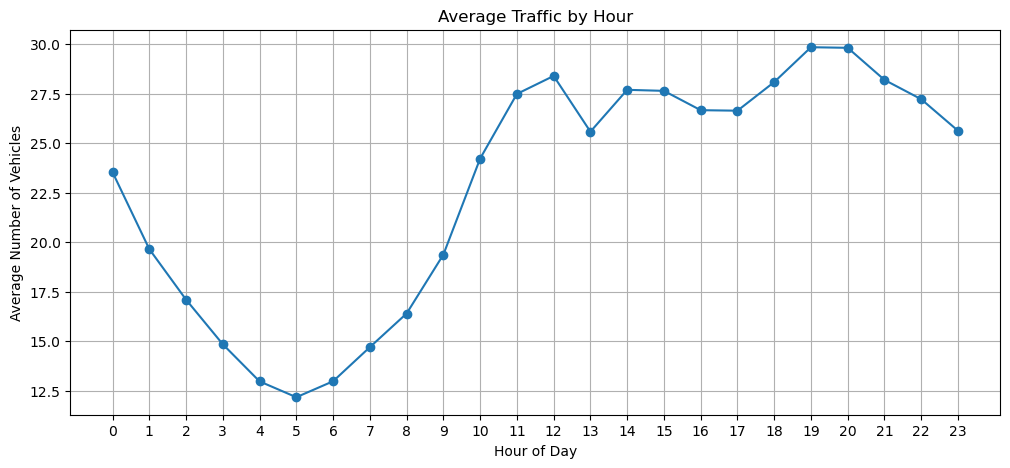

In [12]:
hourly_traffic = df.groupby('Hour')['Vehicles'].mean()

plt.figure(figsize=(12, 5))
plt.plot(hourly_traffic.index, hourly_traffic.values, marker='o')
plt.title('Average Traffic by Hour')
plt.xlabel('Hour of Day')
plt.ylabel('Average Number of Vehicles')
plt.xticks(range(24))
plt.grid(True)
plt.show()

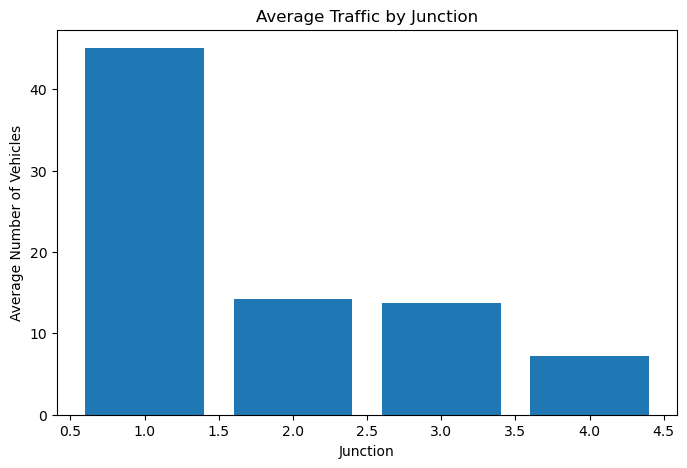

In [13]:
junction_traffic = df.groupby('Junction')['Vehicles'].mean()

plt.figure(figsize=(8, 5))
plt.bar(junction_traffic.index, junction_traffic.values)

plt.title('Average Traffic by Junction')
plt.xlabel('Junction')
plt.ylabel('Average Number of Vehicles')

plt.show()

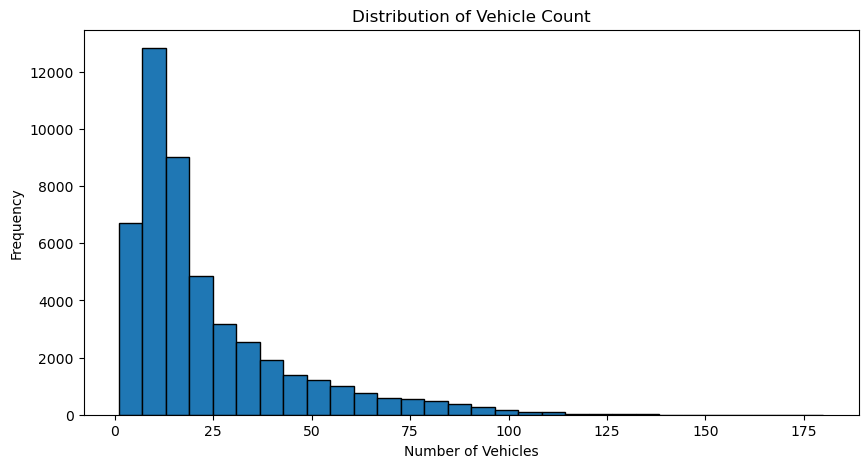

In [14]:
plt.figure(figsize=(10, 5))

plt.hist(df['Vehicles'], bins=30, edgecolor='black')

plt.title('Distribution of Vehicle Count')
plt.xlabel('Number of Vehicles')
plt.ylabel('Frequency')

plt.show()

In [15]:
low_threshold = df['Vehicles'].quantile(0.50)
high_threshold = df['Vehicles'].quantile(0.75)

print("Low Traffic: <=", low_threshold)
print("Medium Traffic:", low_threshold, "to", high_threshold)
print("High Traffic: >", high_threshold)

Low Traffic: <= 15.0
Medium Traffic: 15.0 to 29.0
High Traffic: > 29.0


In [16]:
def get_congestion_level(vehicles):
    if vehicles <= low_threshold:
        return 'Low'
    elif vehicles <= high_threshold:
        return 'Medium'
    else:
        return 'High'


df['Congestion_Level'] = df['Vehicles'].apply(get_congestion_level)

df[['Vehicles', 'Congestion_Level']].head(10)

,Vehicles,Congestion_Level
0,15,Low
1,13,Low
2,10,Low
3,7,Low
4,9,Low
5,6,Low
6,9,Low
7,8,Low
8,11,Low
9,12,Low


Congestion_Level
Low       24479
High      12003
Medium    11638
Name: count, dtype: int64


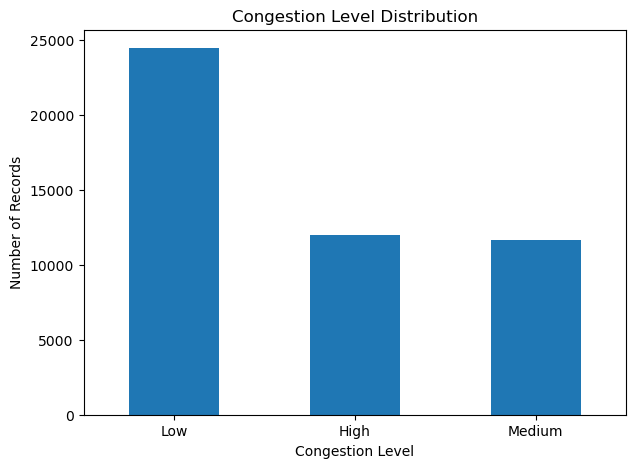

In [17]:
congestion_counts = df['Congestion_Level'].value_counts()

print(congestion_counts)

plt.figure(figsize=(7, 5))
congestion_counts.plot(kind='bar')

plt.title('Congestion Level Distribution')
plt.xlabel('Congestion Level')
plt.ylabel('Number of Records')
plt.xticks(rotation=0)

plt.show()

In [18]:
X = df[['Junction', 'Hour', 'Day', 'Month', 'DayOfWeek', 'Vehicles']]
y = df['Congestion_Level']

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (48120, 6)
Target shape: (48120,)


In [19]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (38496, 6)
Testing data: (9624, 6)


In [20]:
model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight='balanced'
)

model.fit(X_train, y_train)

print("Model training completed successfully!")

Model training completed successfully!


In [21]:
y_pred = model.predict(X_test)

print("Prediction completed successfully!")

Prediction completed successfully!


In [22]:
accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", accuracy)
print("Accuracy Percentage:", round(accuracy * 100, 2), "%")

Model Accuracy: 1.0
Accuracy Percentage: 100.0 %


In [23]:
X = df[['Junction', 'Hour', 'Day', 'Month', 'DayOfWeek']]
y = df['Congestion_Level']

print("Features:", X.columns.tolist())
print("Target:", y.name)

Features: ['Junction', 'Hour', 'Day', 'Month', 'DayOfWeek']
Target: Congestion_Level


In [24]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (38496, 5)
Testing data: (9624, 5)


In [25]:
model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight='balanced'
)

model.fit(X_train, y_train)

print("New model training completed!")

New model training completed!


In [26]:
y_pred = model.predict(X_test)

print("Prediction completed!")

Prediction completed!


In [27]:
accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", round(accuracy, 4))
print("Accuracy Percentage:", round(accuracy * 100, 2), "%")

Model Accuracy: 0.787
Accuracy Percentage: 78.7 %


In [28]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

        High       0.81      0.83      0.82      2401
         Low       0.85      0.88      0.86      4896
      Medium       0.61      0.54      0.57      2327

    accuracy                           0.79      9624
   macro avg       0.76      0.75      0.75      9624
weighted avg       0.78      0.79      0.78      9624



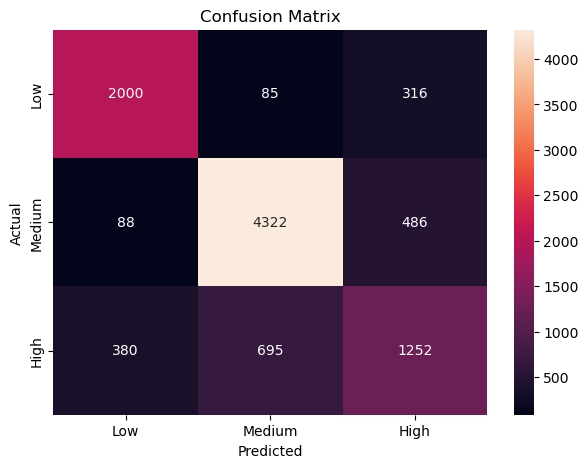

In [29]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    xticklabels=['Low', 'Medium', 'High'],
    yticklabels=['Low', 'Medium', 'High']
)

plt.title('Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')

plt.show()

In [32]:
import joblib
import os

# Save model in the same folder as the notebook
model_path = "traffic_congestion_model.pkl"

joblib.dump(model, model_path)

print("Model saved successfully!")
print("Saved at:", os.path.abspath(model_path))

Model saved successfully!
Saved at: C:\Users\uttam\My_Project\Smart Traffic Monitoring And Congestion Prediction\traffic_congestion_model.pkl


In [33]:
feature_columns = X.columns.tolist()

joblib.dump(feature_columns, "feature_columns.pkl")

print("Feature columns saved successfully!")
print(feature_columns)

Feature columns saved successfully!
['Junction', 'Hour', 'Day', 'Month', 'DayOfWeek']
